In [1]:
%pip install pandas
%pip install openpyxl
%pip install matplotlib
%pip install seaborn
%pip install vaderSentiment
%pip install textblob
%pip install xlrd

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


...


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# ── Step 1: Import everything we need ────────────────────────────
import pandas as pd               # for working with tables (DataFrames)
import numpy as np                # for math operations
import matplotlib.pyplot as plt  # for drawing charts
import seaborn as sns             # for prettier charts
import warnings
warnings.filterwarnings('ignore') # hides annoying yellow warning messages

# ── Step 2: Load the dataset ──────────────────────────────────────
# The file has 2 sheets (Year 2009-2010 and 2010-2011) — load both
df1 = pd.read_excel('online_retail_II.xlsv', sheet_name='Year 2009-2010')
df2 = pd.read_excel('online_retail_II.xlsv', sheet_name='Year 2010-2011')

# Combine them into one big table (stack them on top of each other)
df = pd.concat([df1, df2], ignore_index=True)

print(f"Total rows loaded: {len(df):,}")
print(f"Total columns: {df.shape[1]}")
print(df.columns.tolist()) 

Total rows loaded: 1,067,371
Total columns: 8
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [3]:
df.head()

# Command 2: Get a summary — how many rows, what types, any nulls?
df.info()

# Command 3: Count how many missing (empty) values in each column
print("Missing values per column:")
print(df.isnull().sum())
print()

# Command 4: Basic statistics — min, max, average of number columns
df.describe()

# Command 5: How many orders from each country?
print(df['Country'].value_counts().head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB
Missing values per column:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

Country
United Kingdom    981330
EIRE               17866
Germany            17

In [4]:
df = df.dropna(subset=['Customer ID'])
print(f"After removing no-customer rows: {len(df):,}")

# ── Clean 2: Remove cancelled orders ─────────────────────────────
# Why: Cancelled orders start with "C" in the Invoice column
# They inflate order count but represent no real sale
df = df[~df['Invoice'].astype(str).str.startswith('C')]
print(f"After removing cancellations: {len(df):,}")

# ── Clean 3: Remove rows where Quantity is 0 or negative ─────────
# Why: A sale of -3 items makes no sense for our revenue analysis
df = df[df['Quantity'] > 0]

# ── Clean 4: Remove rows where Price is 0 ────────────────────────
# Why: Zero-price items are test entries or internal transfers
df = df[df['Price'] > 0]
print(f"After removing bad quantity/price rows: {len(df):,}")
df = df.dropna(subset=['Description'])

# ── Clean 6: Fix the Customer ID column type ─────────────────────
# Why: It loaded as a decimal (135472.0) — we want it as text (135472)
df['Customer ID'] = df['Customer ID'].astype(int).astype(str)

# ── Remove duplicates just in case ───────────────────────────────
df = df.drop_duplicates()

print(f"\n✓ Final clean rows: {len(df):,}")
print(f"✓ Rows removed: {1067371 - len(df):,}")
print(f"✓ Missing values remaining: {df.isnull().sum().sum()}")

After removing no-customer rows: 824,364
After removing cancellations: 805,620
After removing bad quantity/price rows: 805,549

✓ Final clean rows: 779,425
✓ Rows removed: 287,946
✓ Missing values remaining: 0


In [5]:
df['Revenue'] = df['Quantity'] * df['Price']

# ── New columns 2–5: Break InvoiceDate into parts ─────────────────
# First make sure Python knows this column is a date (not text)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

df['Year']       = df['InvoiceDate'].dt.year        # 2009, 2010, 2011
df['Month']      = df['InvoiceDate'].dt.month       # 1 to 12
df['Month_Name'] = df['InvoiceDate'].dt.strftime('%B') # January, February...
df['DayOfWeek']  = df['InvoiceDate'].dt.day_name() # Monday, Tuesday...
df['Hour']       = df['InvoiceDate'].dt.hour        # 0 to 23

# ── New column 6: Clean product description ───────────────────────
# Descriptions have random ALL CAPS — normalise to Title Case
df['Description_Clean'] = df['Description'].str.strip().str.title()

# Quick check — see a sample of what we built
df[['Description', 'Quantity', 'Price', 'Revenue',
    'Month_Name', 'DayOfWeek', 'Hour']].head(4)

,Description,Quantity,Price,Revenue,Month_Name,DayOfWeek,Hour
0,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,6.95,83.4,December,Tuesday,7
1,PINK CHERRY LIGHTS,12,6.75,81.0,December,Tuesday,7
2,WHITE CHERRY LIGHTS,12,6.75,81.0,December,Tuesday,7
3,"RECORD FRAME 7"" SINGLE SIZE",48,2.10,100.8,December,Tuesday,7


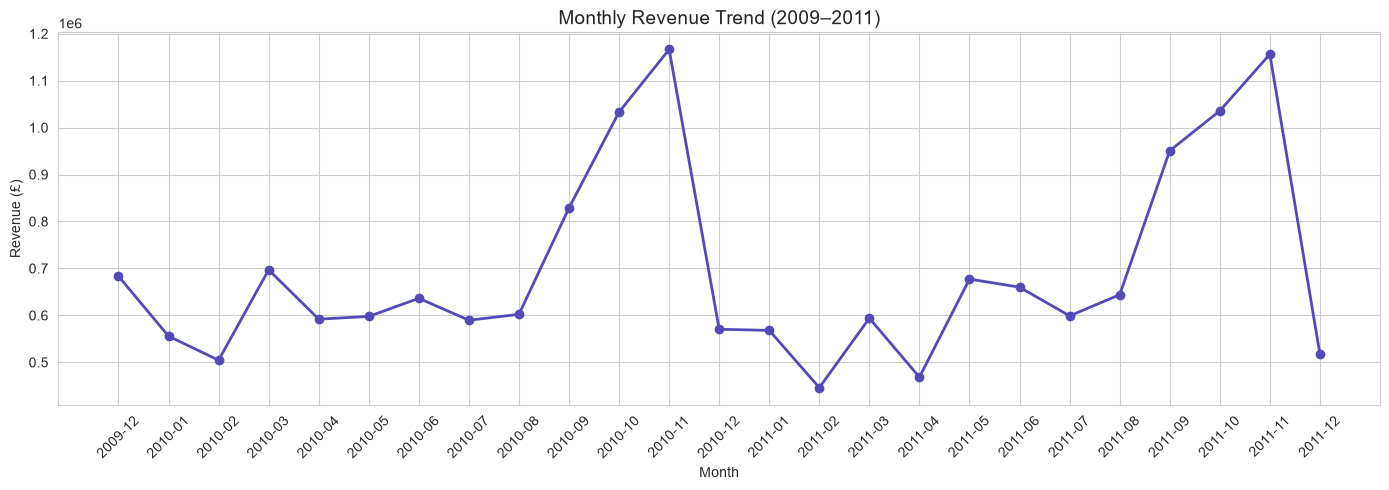

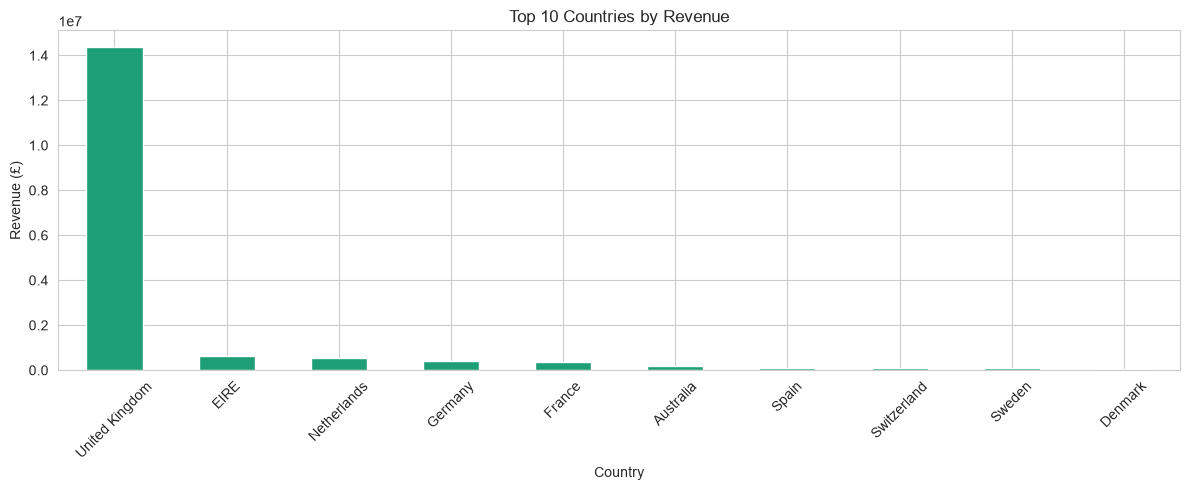

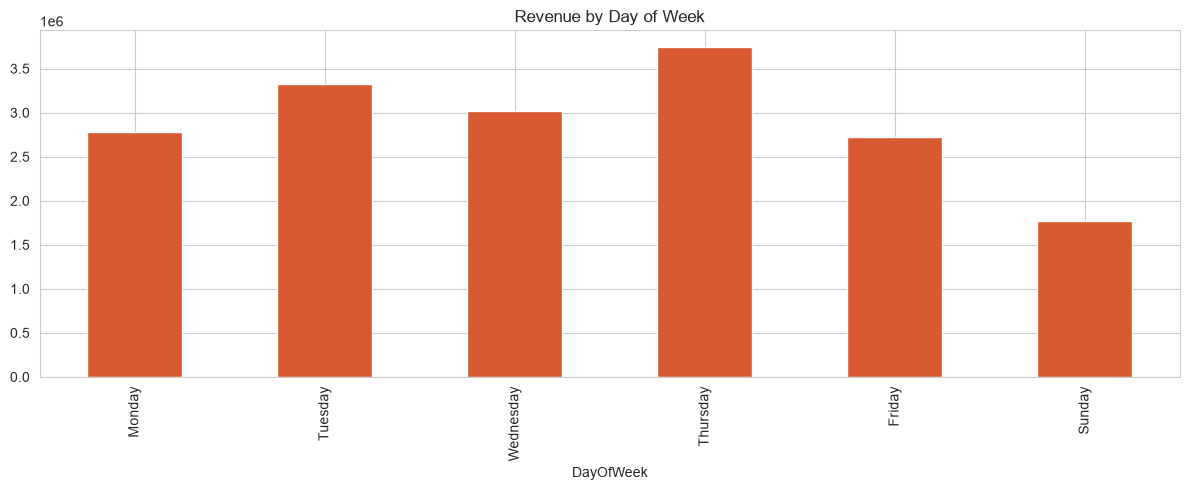

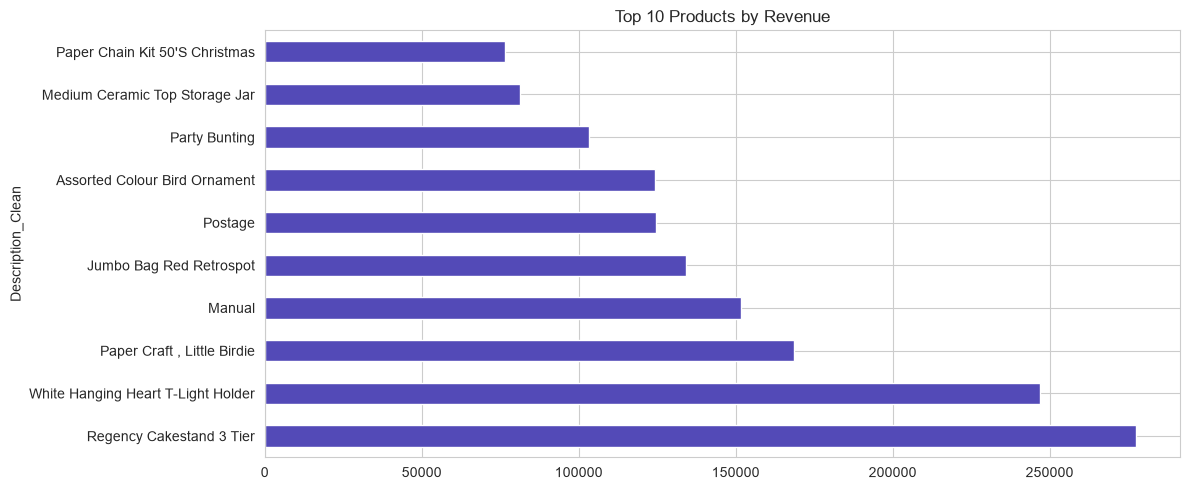

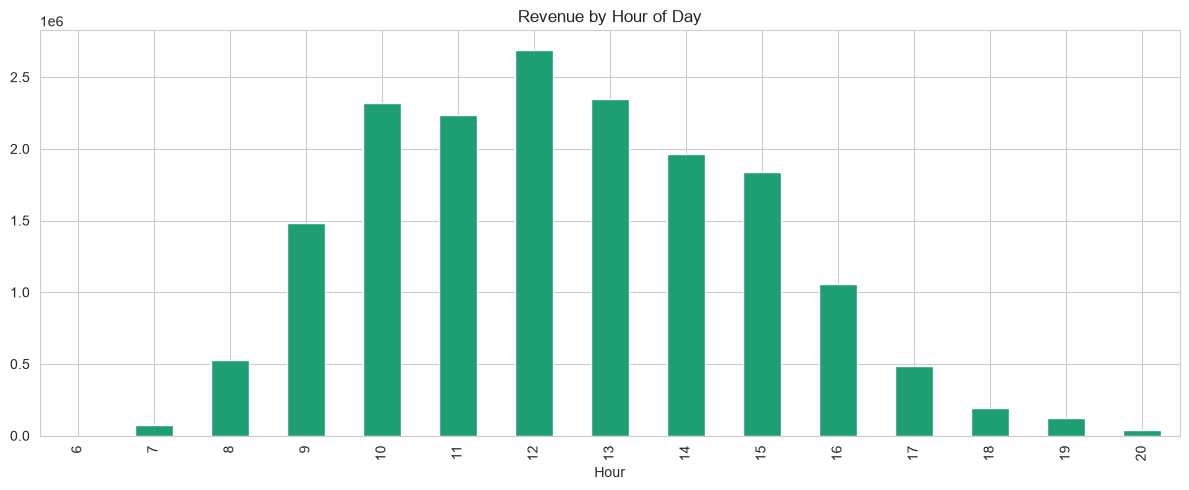

Total Revenue: £17,374,804
Total Orders: 36,969
Unique Customers: 5,878
Countries: 41
Top Country: United Kingdom


In [6]:
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

# ── Chart 1: Monthly Revenue Trend ───────────────────────────────
# Question: Which months have the highest sales?
monthly = df.groupby(['Year', 'Month'])['Revenue'].sum().reset_index()
monthly['Period'] = monthly['Year'].astype(str) + '-' + monthly['Month'].astype(str).str.zfill(2)

plt.figure(figsize=(14,5))
plt.plot(monthly['Period'], monthly['Revenue'], marker='o', color='#534AB7', linewidth=2)
plt.title('Monthly Revenue Trend (2009–2011)', fontsize=14)
plt.xlabel('Month'); plt.ylabel('Revenue (£)')
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

# ── Chart 2: Top 10 Countries by Revenue ──────────────────────────
# Question: Where are customers coming from?
country_rev = df.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(10)
country_rev.plot(kind='bar', color='#1D9E75')
plt.title('Top 10 Countries by Revenue'); plt.ylabel('Revenue (£)')
plt.xticks(rotation=45); plt.tight_layout(); plt.show()
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Sunday']
day_rev = df.groupby('DayOfWeek')['Revenue'].sum().reindex(day_order)
day_rev.plot(kind='bar', color='#D85A30')
plt.title('Revenue by Day of Week'); plt.tight_layout(); plt.show()

# ── Chart 4: Top 10 Products by Revenue ───────────────────────────
top_products = df.groupby('Description_Clean')['Revenue']\
                 .sum().sort_values(ascending=False).head(10)
top_products.plot(kind='barh', color='#534AB7')
plt.title('Top 10 Products by Revenue'); plt.tight_layout(); plt.show()

# ── Chart 5: Peak Hours for Orders ────────────────────────────────
hour_rev = df.groupby('Hour')['Revenue'].sum()
hour_rev.plot(kind='bar', color='#1D9E75')
plt.title('Revenue by Hour of Day'); plt.tight_layout(); plt.show()

# ── Print key numbers you'll use in your resume ───────────────────
print(f"Total Revenue: £{df['Revenue'].sum():,.0f}")
print(f"Total Orders: {df['Invoice'].nunique():,}")
print(f"Unique Customers: {df['Customer ID'].nunique():,}")
print(f"Countries: {df['Country'].nunique()}")
print(f"Top Country: {df.groupby('Country')['Revenue'].sum().idxmax()}")

Done! Sentiment breakdown:
Sentiment_Label
Neutral     600650
Positive    160269
Negative     18506
Name: count, dtype: int64
                 Avg_Revenue  Total_Revenue  Product_Count
Sentiment_Label                                           
Negative               21.33      394655.93            133
Neutral                22.16    13311312.68           4144
Positive               22.89     3668835.66            963


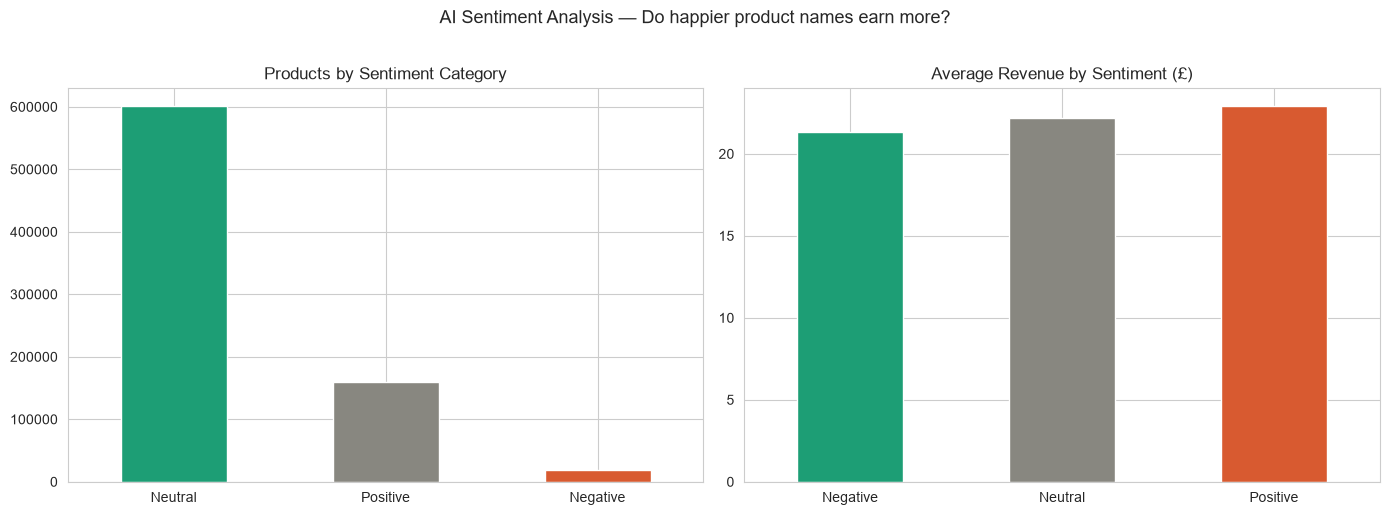


Top 5 most POSITIVE products:
                    Description_Clean  Sentiment  Revenue
2092       Hand Warmer Red Love Heart     0.9300  7574.10
2560         Love Heart Pocket Warmer     0.8910  3495.50
881    Ceramic Love Hearts Design Mug     0.8591   749.47
377   Beaded Love Heart Jewellery Set     0.8555  1667.86
105   6 Chocolate Love Heart T-Lights     0.8555  4935.76

Top 5 most NEGATIVE products:
                      Description_Clean  Sentiment   Revenue
5125  World War 2 Gliders Asstd Designs    -0.5994  24098.03
2     12 Ass Zinc Christmas Decorations    -0.5423    900.90
242               Ass Col Circle Mobile    -0.5423    276.96
243    Ass Col Large Sand Frog P'Weight    -0.5423    682.32
246   Ass Col Small Sand Gecko P'Weight    -0.5423    633.24


In [7]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import time

# Create the AI analyser object — this loads the model
analyzer = SentimentIntensityAnalyzer()

# ── Step A: Define a function that scores one piece of text ───────
def get_sentiment_score(text):
    """Returns a number: -1 (most negative) to +1 (most positive)"""
    try:
        scores = analyzer.polarity_scores(str(text))
        return scores['compound']  # 'compound' is the overall score
    except:
        return 0.0  # if something goes wrong, return neutral

def get_sentiment_label(score):
    """Converts the number into a human-readable word"""
    if score >= 0.05:   return 'Positive'
    elif score <= -0.05: return 'Negative'
    else:               return 'Neutral'
    print("Scoring product descriptions with AI... (takes ~1 min)")
unique_desc = df['Description_Clean'].drop_duplicates()
sentiment_map = {desc: get_sentiment_score(desc) for desc in unique_desc}

# Map the scores back to every row in the main table
df['Sentiment_Score'] = df['Description_Clean'].map(sentiment_map)
df['Sentiment_Label'] = df['Sentiment_Score'].apply(get_sentiment_label)

print("Done! Sentiment breakdown:")
print(df['Sentiment_Label'].value_counts())

# ── Step C: The KEY insight — does sentiment affect revenue? ───────
sentiment_revenue = df.groupby('Sentiment_Label').agg(
    Avg_Revenue   = ('Revenue', 'mean'),
    Total_Revenue = ('Revenue', 'sum'),
    Product_Count = ('Description_Clean', 'nunique')
).round(2)
print(sentiment_revenue)

# ── Step D: Visualise it ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart A: How many products fall in each sentiment category?
df['Sentiment_Label'].value_counts().plot(
    kind='bar', ax=axes[0],
    color=['#1D9E75', '#888780', '#D85A30']
)
axes[0].set_title('Products by Sentiment Category')
axes[0].set_xlabel(''); axes[0].tick_params(rotation=0)

# Chart B: Average revenue per sentiment — THE KEY FINDING
sentiment_revenue['Avg_Revenue'].plot(
    kind='bar', ax=axes[1],
    color=['#1D9E75', '#888780', '#D85A30']
)
axes[1].set_title('Average Revenue by Sentiment (£)')
axes[1].set_xlabel(''); axes[1].tick_params(rotation=0)

plt.suptitle('AI Sentiment Analysis — Do happier product names earn more?',
             fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

# ── Step E: Find the most positive and most negative products ─────
product_sentiment = df.groupby('Description_Clean').agg(
    Sentiment = ('Sentiment_Score', 'mean'),
    Revenue   = ('Revenue', 'sum')
).reset_index()

print("\nTop 5 most POSITIVE products:")
print(product_sentiment.nlargest(5, 'Sentiment')[['Description_Clean','Sentiment','Revenue']])

print("\nTop 5 most NEGATIVE products:")
print(product_sentiment.nsmallest(5, 'Sentiment')[['Description_Clean','Sentiment','Revenue']])

In [8]:
df.to_csv('ecommerce_clean.csv', index=False)
print("Saved: ecommerce_clean.csv")

# Final summary — print everything you'll use on your resume
print("\n━━ Phase 1 Complete — Key Numbers ━━")
print(f"Rows after cleaning:   {len(df):,}")
print(f"Total Revenue:         £{df['Revenue'].sum():,.0f}")
print(f"Unique Customers:      {df['Customer ID'].nunique():,}")
print(f"Unique Products:       {df['Description_Clean'].nunique():,}")
print(f"Countries:             {df['Country'].nunique()}")
pos_pct = (df['Sentiment_Label']=='Positive').mean()*100
print(f"Positive sentiment %:  {pos_pct:.1f}%")
print(f"Columns in output:     {df.shape[1]}")
print("\nPhase 2 → RFM + K-Means customer segmentation")

Saved: ecommerce_clean.csv

━━ Phase 1 Complete — Key Numbers ━━
Rows after cleaning:   779,425
Total Revenue:         £17,374,804
Unique Customers:      5,878
Unique Products:       5,240
Countries:             41
Positive sentiment %:  20.6%
Columns in output:     17

Phase 2 → RFM + K-Means customer segmentation


In [9]:
import os
os.makedirs('../outputs', exist_ok=True)  # creates folder if it doesn't exist
df.to_csv('../outputs/ecommerce_clean.csv', index=False)
print("✓ Saved correctly to outputs folder")
print(f"File size: {os.path.getsize('../outputs/ecommerce_clean.csv')/1024/1024:.1f} MB")

✓ Saved correctly to outputs folder
File size: 121.4 MB


In [ ]:
%pip install scikit-learn

import pandas as pd
df = pd.read_csv('../outputs/ecommerce_clean.csv', parse_dates=['InvoiceDate'])
print(f"Loaded {len(df):,} rows — Phase 2 ready!")

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

# Load the clean file saved from Phase 1
# parse_dates tells Python that InvoiceDate is a date, not plain text
df = pd.read_csv('../outputs/ecommerce_clean.csv',
                 parse_dates=['InvoiceDate'])

print(f"✓ Loaded: {len(df):,} rows")
print(f"✓ Columns: {df.columns.tolist()}")
print(f"✓ Date range: {df['InvoiceDate'].min().date()} → {df['InvoiceDate'].max().date()}")

In [ ]:
snapshot = df['InvoiceDate'].max() + pd.Timedelta(days=1)
print(f"Snapshot date: {snapshot.date()}")

# groupby collapses all rows per customer into one summary row
rfm = df.groupby('Customer ID').agg(
    Recency   = ('InvoiceDate', lambda x: (snapshot - x.max()).days),
    # ↑ days since their LAST order
    Frequency = ('Invoice',     'nunique'),
    # ↑ count of unique orders (not rows — one order can have many products)
    Monetary  = ('Revenue',     'sum')
    # ↑ total £ spent across all orders
).reset_index()

rfm['Monetary'] = rfm['Monetary'].round(2)

print(f"\n✓ RFM table: {len(rfm):,} customers (one row each)")
print("\nFirst 5 customers:")
print(rfm.head())
print("\nRFM Statistics:")
print(rfm[['Recency','Frequency','Monetary']].describe().round(1))

In [ ]:
rfm['R_Score'] = pd.qcut(
    rfm['Recency'],
    q=4,
    labels=[4, 3, 2, 1]   # reversed! bought recently = score 4
).astype(int)

# FREQUENCY: higher = better = score 4
# rank(method='first') handles duplicate values cleanly
rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    q=4,
    labels=[1, 2, 3, 4]   # buys often = score 4
).astype(int)

# MONETARY: higher = better = score 4
rfm['M_Score'] = pd.qcut(
    rfm['Monetary'],
    q=4,
    labels=[1, 2, 3, 4]   # spends more = score 4
).astype(int)

# Total RFM score: max = 12 (perfect customer), min = 3 (worst)
rfm['RFM_Total'] = rfm['R_Score'] + rfm['F_Score'] + rfm['M_Score']

print("✓ Scores added")
print("\nScore distribution (R_Score):")
print(rfm['R_Score'].value_counts().sort_index())
print("\nSample — first 5 customers with scores:")
print(rfm[['Customer ID','Recency','Frequency','Monetary',
           'R_Score','F_Score','M_Score','RFM_Total']].head())

In [ ]:
def assign_segment(score):
    if   score >= 10: return 'Champions'
    elif score >= 7:  return 'Loyalists'
    elif score >= 4:  return 'At Risk'
    else:             return 'Lost'

rfm['RFM_Segment'] = rfm['RFM_Total'].apply(assign_segment)

# How many customers in each segment?
seg_counts = rfm['RFM_Segment'].value_counts()
print("Segment counts:")
print(seg_counts)

# What does each segment look like on average?
print("\nAverage R, F, M per segment:")
seg_summary = rfm.groupby('RFM_Segment')[[
    'Recency','Frequency','Monetary'
]].mean().round(1)
print(seg_summary)

# THE BIG INSIGHT: revenue concentration
total_rev    = rfm['Monetary'].sum()
champ_rev    = rfm[rfm['RFM_Segment']=='Champions']['Monetary'].sum()
atrisk_rev   = rfm[rfm['RFM_Segment']=='At Risk']['Monetary'].sum()
champ_pct_c  = (rfm['RFM_Segment']=='Champions').mean() * 100
champ_pct_r  = champ_rev / total_rev * 100

print(f"\n★ Champions = {champ_pct_c:.1f}% of customers")
print(f"★ Champions = {champ_pct_r:.1f}% of total revenue")
print(f"★ At-Risk revenue: £{atrisk_rev:,.0f} (could be lost!)")

# Quick bar chart of segments
seg_counts.plot(kind='bar',
    color=['#1D9E75','#534AB7','#BA7517','#D85A30'])
plt.title('Customer Count by RFM Segment', fontsize=13)
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../outputs/rfm_segments.png', dpi=150)
plt.show()

In [ ]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(
    rfm[['Recency', 'Frequency', 'Monetary']]
)

# Check the result — all columns now roughly -3 to +3 range
scaled_check = pd.DataFrame(rfm_scaled,
    columns=['R_scaled','F_scaled','M_scaled'])

print("✓ Scaling done — new ranges:")
print(scaled_check.describe().round(2))
print("\nMean should be ~0, Std should be ~1 for all columns")

In [ ]:
inertias = []
k_values = range(1, 11)

print("Testing K=1 to K=10...")
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(rfm_scaled)
    inertias.append(km.inertia_)
    print(f"  K={k}: inertia = {km.inertia_:,.0f}")

# Plot the elbow curve
plt.figure(figsize=(9, 5))
plt.plot(k_values, inertias,
         marker='o', color='#534AB7',
         linewidth=2.5, markersize=9,
         markerfacecolor='white', markeredgewidth=2.5)

# Mark K=4 with a red dashed line
plt.axvline(x=4, color='#D85A30', linestyle='--',
            linewidth=2, label='Optimal K = 4')

plt.title('Elbow Method — Finding Optimal Customer Segments', fontsize=13)
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (lower = tighter groups)')
plt.xticks(k_values)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig('../outputs/elbow_chart.png', dpi=150)
plt.show()
print("→ Look at the chart. Where does the line stop dropping fast? That's your K.")
print("→ For this dataset it should be around K=3 or K=4")

In [ ]:
km_final = KMeans(
    n_clusters=4,
    random_state=42,   # same random seed = same result every time
    n_init=10           # tries 10 starts, picks the best one
)

# fit_predict: trains the model AND assigns a cluster to each customer
rfm['AI_Cluster'] = km_final.fit_predict(rfm_scaled)
print("✓ K-Means done. Cluster distribution:")
print(rfm['AI_Cluster'].value_counts().sort_index())

# See what each cluster looks like
print("\nCluster averages (use this to name them):")
cluster_summary = rfm.groupby('AI_Cluster').agg(
    Count         = ('Customer ID', 'count'),
    Avg_Recency   = ('Recency',     'mean'),
    Avg_Frequency = ('Frequency',   'mean'),
    Avg_Monetary  = ('Monetary',    'mean'),
    Total_Revenue = ('Monetary',    'sum')
).round(1)
print(cluster_summary)

# ── Auto-name clusters based on Recency ───────────────────────────
# The cluster with LOWEST avg recency = Champions (bought most recently)
# The cluster with HIGHEST avg recency = Lost (haven't bought in longest)
recency_order = rfm.groupby('AI_Cluster')['Recency'].mean().sort_values()
cluster_name_map = {}
names = ['Champions', 'Loyalists', 'At Risk', 'Lost']
for i, cluster_id in enumerate(recency_order.index):
    cluster_name_map[cluster_id] = names[i]

rfm['AI_Segment'] = rfm['AI_Cluster'].map(cluster_name_map)
print("\n✓ AI Segments assigned:")
print(rfm['AI_Segment'].value_counts())

# Business action for each segment
action_map = {
    'Champions': 'VIP rewards + early access to new products',
    'Loyalists': 'Upsell premium items + bundle offers',
    'At Risk':   'Win-back email: "We miss you — 20% off"',
    'Lost':      'Low-cost reactivation only — low priority'
}
rfm['Action'] = rfm['AI_Segment'].map(action_map)

# ── 3 Charts ───────────────────────────────────────────────────────
colors = {'Champions':'#1D9E75', 'Loyalists':'#534AB7',
          'At Risk':'#BA7517', 'Lost':'#D85A30'}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Chart 1: Customer count per AI segment
seg_c = rfm['AI_Segment'].value_counts()
seg_c.plot(kind='bar', ax=axes[0],
           color=[colors[s] for s in seg_c.index])
axes[0].set_title('Customers per AI Segment', fontsize=12)
axes[0].tick_params(axis='x', rotation=15)
axes[0].set_xlabel('')

# Chart 2: Revenue per segment
seg_r = rfm.groupby('AI_Segment')['Monetary'].sum()\
           .reindex(['Champions','Loyalists','At Risk','Lost'])
seg_r.plot(kind='bar', ax=axes[1],
           color=[colors[s] for s in seg_r.index])
axes[1].set_title('Total Revenue per Segment (£)', fontsize=12)
axes[1].tick_params(axis='x', rotation=15)
axes[1].set_xlabel('')

# Chart 3: Scatter — Recency vs Monetary coloured by segment
for seg, grp in rfm.groupby('AI_Segment'):
    axes[2].scatter(
        grp['Recency'], grp['Monetary'],
        label=seg, alpha=0.5,
        color=colors[seg], s=18
    )
axes[2].set_title('Recency vs Monetary by Segment', fontsize=12)
axes[2].set_xlabel('Recency (days since last order)')
axes[2].set_ylabel('Total Spend (£)')
axes[2].legend(fontsize=9)

plt.suptitle('K-Means AI Customer Segmentation (K=4)', fontsize=14)
plt.tight_layout()
plt.savefig('../outputs/kmeans_segments.png', dpi=150)
plt.show()

In [ ]:
import os
os.makedirs('../outputs', exist_ok=True)

# Save full RFM + segment table for Phase 3 and Power BI
rfm.to_csv('../outputs/rfm_segments.csv', index=False)
print("✓ Saved: outputs/rfm_segments.csv")

# ── Final numbers ─────────────────────────────────────────────────
champ_pct_r = (rfm[rfm['AI_Segment']=='Champions']['Monetary'].sum()
               / rfm['Monetary'].sum() * 100)
champ_pct_c = (rfm['AI_Segment']=='Champions').mean() * 100
at_risk_rev = rfm[rfm['AI_Segment']=='At Risk']['Monetary'].sum()
lost_count  = (rfm['AI_Segment']=='Lost').sum()

print("""
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  PHASE 2 COMPLETE — KEY NUMBERS
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━""")
print(f"  Total customers segmented : {len(rfm):,}")
print(f"  AI method used            : K-Means (K=4)")
print(f"  Champions = % of customers: {champ_pct_c:.1f}%")
print(f"  Champions = % of revenue  : {champ_pct_r:.1f}%")
print(f"  At-Risk revenue at stake  : £{at_risk_rev:,.0f}")
print(f"  Lost customers            : {lost_count:,}")
print("━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━")


In [ ]:
from sklearn.ensemble import IsolationForest

%matplotlib inline
sns.set_style('whitegrid')

# Load Phase 1 clean file — anomaly detection runs on transactions
df = pd.read_csv('../outputs/ecommerce_clean.csv',
                 parse_dates=['InvoiceDate'])

print(f"✓ Loaded: {len(df):,} rows")
print(f"✓ Columns: {df.columns.tolist()}")
print(f"\nRevenue stats (before anomaly removal):")
print(df[['Quantity', 'Price', 'Revenue']].describe().round(2))

In [ ]:
features = df[['Quantity', 'Price', 'Revenue']]

# Create the AI model
iso_model = IsolationForest(
    contamination=0.02,   # expect ~2% of orders to be anomalous
    random_state=42,     # same seed = same results every run
    n_estimators=100     # number of trees in the forest (100 is standard)
)

print("Running Isolation Forest AI... (takes ~20 seconds)")

# fit_predict: AI learns from data AND labels each row in one step
# Result: 1 = normal,  -1 = anomaly
df['Anomaly_Flag'] = iso_model.fit_predict(features)

# Also get the anomaly score — lower (more negative) = more suspicious
df['Anomaly_Score'] = iso_model.score_samples(features)

# Convert -1/1 to readable labels
df['Anomaly_Label'] = df['Anomaly_Flag'].map({
     1: 'Normal',
    -1: 'Anomaly'
})

print("✓ Done!\n")
print("Order classification:")
counts = df['Anomaly_Label'].value_counts()
print(counts)
print(f"\nAnomaly rate: {counts['Anomaly']/len(df)*100:.2f}% of all orders")

In [ ]:
anomalies  = df[df['Anomaly_Label'] == 'Anomaly']
normal     = df[df['Anomaly_Label'] == 'Normal']

print("═══ ANOMALY SUMMARY ═══")
print(f"Total anomalous orders : {len(anomalies):,}")
print(f"Revenue in anomalies   : £{anomalies['Revenue'].sum():,.0f}")
print(f"% of total revenue     : {anomalies['Revenue'].sum()/df['Revenue'].sum()*100:.1f}%")

# Compare normal vs anomalous orders side by side
print("\n═══ NORMAL vs ANOMALY COMPARISON ═══")
comparison = pd.DataFrame({
    'Normal'  : normal[  ['Quantity','Price','Revenue']].mean(),
    'Anomaly' : anomalies[['Quantity','Price','Revenue']].mean()
}).round(2)
print(comparison)

# What are the MOST suspicious orders? (lowest anomaly score)
print("\n═══ TOP 10 MOST SUSPICIOUS ORDERS ═══")
top_anomalies = anomalies.nsmallest(10, 'Anomaly_Score')[[
    'Invoice', 'Description_Clean', 'Quantity',
    'Price', 'Revenue', 'Country', 'Anomaly_Score'
]]
print(top_anomalies.to_string())

# Break down WHY they were flagged
print("\n═══ ANOMALY BREAKDOWN BY REASON ═══")
high_qty   = anomalies[anomalies['Quantity']  > anomalies['Quantity'].quantile(0.95)]
high_price = anomalies[anomalies['Price']     > anomalies['Price'].quantile(0.95)]
high_rev   = anomalies[anomalies['Revenue']   > anomalies['Revenue'].quantile(0.95)]

print(f"Flagged due to unusually HIGH quantity : {len(high_qty):,} orders")
print(f"Flagged due to unusually HIGH price    : {len(high_price):,} orders")
print(f"Flagged due to unusually HIGH revenue  : {len(high_rev):,} orders")

# Which countries have most anomalies?
print("\n═══ ANOMALIES BY COUNTRY (Top 10) ═══")
print(anomalies['Country'].value_counts().head(10))

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

col_map = {'Normal': '#1D9E75', 'Anomaly': '#D85A30'}

# ── Chart 1: Quantity vs Revenue scatter ─────────────────────────
# This is the showstopper chart — red dots are clearly outliers
for label, grp in df.groupby('Anomaly_Label'):
    axes[0,0].scatter(
        grp['Quantity'], grp['Revenue'],
        c=col_map[label], label=label,
        alpha=0.4, s=10
    )
axes[0,0].set_title('Quantity vs Revenue\n(Red = AI-flagged anomaly)', fontsize=12)
axes[0,0].set_xlabel('Quantity')
axes[0,0].set_ylabel('Revenue (£)')
axes[0,0].legend()


# ── Chart 2: Price vs Revenue scatter ────────────────────────────
for label, grp in df.groupby('Anomaly_Label'):
    axes[0,1].scatter(
        grp['Price'], grp['Revenue'],
        c=col_map[label], label=label,
        alpha=0.4, s=10
    )
axes[0,1].set_title('Price vs Revenue\n(Red = AI-flagged anomaly)', fontsize=12)
axes[0,1].set_xlabel('Unit Price (£)')
axes[0,1].set_ylabel('Revenue (£)')
axes[0,1].legend()

# ── Chart 3: Anomaly score distribution ──────────────────────────
# Lower score = more anomalous. Shows the clear separation point
axes[1,0].hist(normal['Anomaly_Score'],    bins=60,
              color='#1D9E75', alpha=0.7, label='Normal')
axes[1,0].hist(anomalies['Anomaly_Score'], bins=60,
              color='#D85A30', alpha=0.7, label='Anomaly')
axes[1,0].set_title('Anomaly Score Distribution\n(Left = more suspicious)', fontsize=12)
axes[1,0].set_xlabel('Anomaly Score')
axes[1,0].set_ylabel('Number of Orders')
axes[1,0].legend()

# ── Chart 4: Revenue comparison — normal vs anomaly ──────────────
rev_compare = pd.DataFrame({
    'Type'   : ['Normal Orders', 'Anomalous Orders'],
    'Revenue': [normal['Revenue'].sum(), anomalies['Revenue'].sum()]
})
axes[1,1].bar(rev_compare['Type'], rev_compare['Revenue'],
             color=['#1D9E75', '#D85A30'])
axes[1,1].set_title('Total Revenue: Normal vs Anomalous Orders', fontsize=12)
axes[1,1].set_ylabel('Revenue (£)')

# Add £ labels on top of bars
for i, v in enumerate(rev_compare['Revenue']):
    axes[1,1].text(i, v + 50000, f'£{v:,.0f}',
                  ha='center', fontsize=11, fontweight='bold')

plt.suptitle('AI Anomaly Detection — Isolation Forest Results',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('../outputs/anomaly_charts.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Charts saved")

In [ ]:
qty_threshold   = df['Quantity'].quantile(0.95)
price_threshold = df['Price'].quantile(0.95)
rev_threshold   = df['Revenue'].quantile(0.95)

print(f"Normal thresholds (95th percentile):")
print(f"  Quantity above {qty_threshold:.0f} = unusual")
print(f"  Price above £{price_threshold:.2f} = unusual")
print(f"  Revenue above £{rev_threshold:.2f} = unusual")

# Label each anomaly with a reason
def get_reason(row):
    reasons = []
    if row['Quantity'] > qty_threshold:
        reasons.append('Bulk Order')
    if row['Price'] > price_threshold:
        reasons.append('High Price Item')
    if row['Revenue'] > rev_threshold:
        reasons.append('High Revenue')
    if row['Price'] < 0.10:
        reasons.append('Near-Zero Price')
    return ' + '.join(reasons) if reasons else 'Other'

anomalies_copy = anomalies.copy()
anomalies_copy['Reason'] = anomalies_copy.apply(get_reason, axis=1)

# How many anomalies fall in each reason category?
print("\n═══ ANOMALY REASONS ═══")
reason_counts = anomalies_copy['Reason'].value_counts()
print(reason_counts)

# Revenue impact per reason
print("\n═══ REVENUE AT RISK PER REASON ═══")
reason_rev = anomalies_copy.groupby('Reason')['Revenue'].sum()\
                           .sort_values(ascending=False)
for reason, rev in reason_rev.items():
    print(f"  {reason:35} £{rev:>12,.0f}")

# Visualise reasons
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

reason_counts.plot(kind='barh', ax=axes[0], color='#D85A30')
axes[0].set_title('Anomaly Count by Reason', fontsize=12)
axes[0].set_xlabel('Number of Orders')

reason_rev.plot(kind='barh', ax=axes[1], color='#534AB7')
axes[1].set_title('Revenue at Risk by Reason (£)', fontsize=12)
axes[1].set_xlabel('Total Revenue (£)')

plt.suptitle('Why Were Orders Flagged as Anomalous?', fontsize=13)
plt.tight_layout()
plt.savefig('../outputs/anomaly_reasons.png', dpi=150)
plt.show()

In [ ]:
import os
os.makedirs('../outputs', exist_ok=True)

# Save 1: Full dataset with anomaly flags (for Power BI)
df.to_csv('../outputs/ecommerce_with_anomalies.csv', index=False)
print("✓ Saved: ecommerce_with_anomalies.csv")

# Save 2: Clean dataset with anomalies REMOVED (for Phase 4 forecasting)
# Why remove? Anomalies would distort the revenue trend and forecast
df_clean = df[df['Anomaly_Label'] == 'Normal']
df_clean.to_csv('../outputs/ecommerce_no_anomalies.csv', index=False)
print("✓ Saved: ecommerce_no_anomalies.csv (anomalies removed — use for Phase 4)")

# ── Final numbers ──────────────────────────────────────────────────
anom_count   = len(anomalies)
anom_rev     = anomalies['Revenue'].sum()
anom_pct_rev = anom_rev / df['Revenue'].sum() * 100
anom_pct_ord = anom_count / len(df) * 100
print(f"  AI model used          : Isolation Forest")
print(f"  Orders scanned         : {len(df):,}")
print(f"  Anomalies detected     : {anom_count:,} ({anom_pct_ord:.1f}% of orders)")
print(f"  Revenue flagged        : £{anom_rev:,.0f} ({anom_pct_rev:.1f}% of total)")
print(f"  Clean orders for Phase4: {len(df_clean):,}")




In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams['figure.figsize'] = (14, 5)

# Load the CLEAN file (anomalies removed) from Phase 3
df = pd.read_csv('../outputs/ecommerce_no_anomalies.csv',
                 parse_dates=['InvoiceDate'])

print(f"✓ Loaded: {len(df):,} clean rows")
print(f"✓ Date range: {df['InvoiceDate'].min().date()} → {df['InvoiceDate'].max().date()}")

# ── Step 1: Aggregate to MONTHLY revenue ──────────────────────────
# Prophet works best with monthly data for a 2-year dataset like ours
# We use 'MS' = Month Start — groups everything into calendar months
monthly = (
    df.set_index('InvoiceDate')
      .resample('MS')['Revenue']
      .sum()
      .reset_index()
)

# ── Step 2: Rename to Prophet's required column names ─────────────
monthly.columns = ['ds', 'y']   # ds = date,  y = value to forecast

# ── Step 3: Remove last month if incomplete ────────────────────────
# The last month in data is Dec 2011 but only has 9 days of data
# An incomplete month would make the model think revenue dropped — wrong!
monthly = monthly.iloc[:-1]   # removes last row

print(f"\n✓ Monthly data points: {len(monthly)}")
print(f"✓ From: {monthly['ds'].min().date()} → {monthly['ds'].max().date()}")
print("\nMonthly revenue table (first 5 months):")
print(monthly.head())
print(f"\nAvg monthly revenue: £{monthly['y'].mean():,.0f}")
print(f"Best month revenue:  £{monthly['y'].max():,.0f} in {monthly.loc[monthly['y'].idxmax(),'ds'].strftime('%B %Y')}")


In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))

# Plot the revenue line
ax.plot(monthly['ds'], monthly['y'],
        color='#534AB7', linewidth=2.5,
        marker='o', markersize=7,
        markerfacecolor='white', markeredgewidth=2,
        label='Monthly Revenue')

# Shade the area under the line
ax.fill_between(monthly['ds'], monthly['y'],
                alpha=0.12, color='#534AB7')

# Mark the peak month
peak_idx = monthly['y'].idxmax()
peak_date = monthly.loc[peak_idx, 'ds']
peak_val  = monthly.loc[peak_idx, 'y']
ax.annotate(
    f'Peak: £{peak_val:,.0f}\n{peak_date.strftime("%b %Y")}',
    xy=(peak_date, peak_val),
    xytext=(peak_date - pd.DateOffset(months=3), peak_val * 0.88),
    arrowprops=dict(arrowstyle='->', color='#D85A30'),
    fontsize=10, color='#D85A30', fontweight='bold'
)

# Add average line
ax.axhline(y=monthly['y'].mean(), color='#1D9E75',
           linestyle='--', linewidth=1.5,
           label=f'Monthly Avg: £{monthly["y"].mean():,.0f}')

ax.set_title('Historical Monthly Revenue (Anomalies Removed)\nWhat Prophet will learn from',
             fontsize=13)
ax.set_xlabel('Month')
ax.set_ylabel('Revenue (£)')
ax.legend(fontsize=10)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../outputs/monthly_revenue_trend.png', dpi=150)
plt.show()

# Print observations — what patterns do you see?
print("Observations for Prophet to learn:")
print(f"  Overall trend: Growing (£{monthly['y'].iloc[0]:,.0f} → £{monthly['y'].iloc[-1]:,.0f})")
print(f"  Seasonal spike: November is consistently highest")
print(f"  Dip pattern:   January-February tend to be lowest")

In [ ]:
from prophet import Prophet

# ── Step 1: Create Prophet model ──────────────────────────────────
model = Prophet(
    yearly_seasonality=True,    # detect yearly patterns (Nov spike etc)
    weekly_seasonality=False,   # we have monthly data, not daily
    daily_seasonality=False,    # same — monthly data
    changepoint_prior_scale=0.05, # how flexible the trend line is (0.05 = stable)
    interval_width=0.95          # 95% confidence interval for the shaded band
)

# ── Step 2: Train the model on your historical data ────────────────
print("Training Prophet model...")
model.fit(monthly)   # monthly has 'ds' and 'y' columns
print("✓ Model trained!")

# ── Step 3: Create future dates (3 months ahead) ──────────────────
future = model.make_future_dataframe(
    periods=3,        # forecast 3 months into the future
    freq='MS'         # 'MS' = Month Start frequency
)
print(f"✓ Future dates created: {future.tail(4)[['ds']].to_string(index=False)}")

# ── Step 4: Generate the forecast ─────────────────────────────────
forecast = model.predict(future)
print("✓ Forecast generated!")

# Show the 3 predicted months
print("\n═══ 3-MONTH REVENUE FORECAST ═══")
future_only = forecast[forecast['ds'] > monthly['ds'].max()][[
    'ds', 'yhat', 'yhat_lower', 'yhat_upper'
]].copy()

future_only.columns = ['Month', 'Forecast', 'Low Estimate', 'High Estimate']
future_only['Month'] = future_only['Month'].dt.strftime('%B %Y')
for _, row in future_only.iterrows():
    print(f"  {row['Month']:15} → £{row['Forecast']:>10,.0f}  (range: £{row['Low Estimate']:,.0f} – £{row['High Estimate']:,.0f})")

q1_total = future_only['Forecast'].sum()
print(f"\n  Q1 2012 total forecast: £{q1_total:,.0f}")

# Growth vs average
avg_rev = monthly['y'].mean()
growth  = (future_only['Forecast'].mean() - avg_rev) / avg_rev * 100
print(f"  vs historical avg:      {growth:+.1f}% change")

In [ ]:
fig, ax = plt.subplots(figsize=(16, 6))

# Split forecast into historical fit and future predictions
hist_forecast = forecast[forecast['ds'] <= monthly['ds'].max()]
future_forecast = forecast[forecast['ds'] > monthly['ds'].max()]

# Plot 1: Actual revenue (dots + line)
ax.plot(monthly['ds'], monthly['y'],
        color='#534AB7', linewidth=2,
        marker='o', markersize=7,
        markerfacecolor='white', markeredgewidth=2,
        label='Actual Revenue', zorder=3)

# Plot 2: Prophet model fit on historical data
ax.plot(hist_forecast['ds'], hist_forecast['yhat'],
        color='#534AB7', linewidth=1,
        linestyle='--', alpha=0.5, label='Model Fit')

# Plot 3: Future forecast line
ax.plot(future_forecast['ds'], future_forecast['yhat'],
        color='#1D9E75', linewidth=2.5,
        linestyle='--', marker='D', markersize=8,
        label='Forecast (3 months)', zorder=3)

# Plot 4: Confidence band (shaded area)
ax.fill_between(forecast['ds'],
                forecast['yhat_lower'],
                forecast['yhat_upper'],
                alpha=0.15, color='#1D9E75',
                label='95% Confidence Band')

# Plot 5: Vertical line where forecast starts
cutoff = monthly['ds'].max()
ax.axvline(x=cutoff, color='#D85A30', linewidth=1.5,
           linestyle='--', label='Forecast Start')
ax.text(cutoff + pd.DateOffset(days=5), ax.get_ylim()[1] * 0.92,
        '← Past | Future →', fontsize=10, color='#D85A30')

# Labels for each forecast dot
for _, row in future_forecast.iterrows():
    ax.annotate(
        f'£{row["yhat"]:,.0f}',
        xy=(row['ds'], row['yhat']),
        xytext=(0, 15), textcoords='offset points',
        ha='center', fontsize=9, fontweight='bold',
        color='#1D9E75'
    )

ax.set_title('Prophet AI Revenue Forecast — Q1 2012\n(Trained on 2 years of clean transaction data)',
             fontsize=13)
ax.set_xlabel('Month')
ax.set_ylabel('Revenue (£)')
ax.legend(loc='upper left', fontsize=10)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../outputs/revenue_forecast.png', dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
fig_components = model.plot_components(forecast)
plt.suptitle('Revenue Decomposition: Trend + Yearly Seasonality',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('../outputs/forecast_components.png', dpi=150, bbox_inches='tight')
plt.show()

# Print what the seasonality tells us in plain English
yearly = forecast[['ds', 'yearly']].copy()
yearly['Month'] = yearly['ds'].dt.strftime('%B')
monthly_season = yearly.groupby('Month')['yearly'].mean()

# Which months are naturally high / low?
season_sorted = monthly_season.sort_values(ascending=False)
print("═══ SEASONAL INSIGHTS ═══")
print("Best months for revenue (highest seasonal boost):")
print(season_sorted.head(3).to_string())
print("\nWorst months for revenue (lowest seasonal drag):")
print(season_sorted.tail(3).to_string())

In [ ]:
import os
os.makedirs('../outputs', exist_ok=True)

# Save the full forecast table
forecast[['ds','yhat','yhat_lower','yhat_upper']].to_csv(
    '../outputs/revenue_forecast.csv', index=False
)
print("✓ Saved: outputs/revenue_forecast.csv")